<a href="https://colab.research.google.com/github/sandeep838116/mathematics/blob/main/Linear_algebra_03(Matrix_transformation_and_eigen_vectors).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformations as matrices


A **linear transformation** $T: \mathbb{R}^n \to \mathbb{R}^m$ is a function that maps vectors from $\mathbb{R}^n$ to $\mathbb{R}^m$ while preserving vector addition and scalar multiplication:

$$T(\mathbf{u} + \mathbf{v}) = T(\mathbf{u}) + T(\mathbf{v}) \quad \text{and} \quad T(c\mathbf{u}) = cT(\mathbf{u})$$

Every linear transformation can be represented uniquely by an $m \times n$ matrix $\mathbf{A}$, such that applying the transformation is equivalent to matrix-vector multiplication:

$$T(\mathbf{x}) = \mathbf{A}\mathbf{x}$$

---

#### How to Construct the Transformation Matrix $\mathbf{A}$
The columns of $\mathbf{A}$ are simply the transformed **standard basis vectors** $\mathbf{e}_1, \mathbf{e}_2, \dots, \mathbf{e}_n$:

$$\mathbf{A} = \begin{bmatrix} T(\mathbf{e}_1) & T(\mathbf{e}_2) & \cdots & T(\mathbf{e}_n) \end{bmatrix}$$

For any vector $\mathbf{x} = x_1\mathbf{e}_1 + x_2\mathbf{e}_2 + \dots + x_n\mathbf{e}_n$:

$$T(\mathbf{x}) = x_1 T(\mathbf{e}_1) + x_2 T(\mathbf{e}_2) + \dots + x_n T(\mathbf{e}_n) = \mathbf{A}\mathbf{x}$$

---

#### Common 2D Geometric Transformation Matrices

| Transformation | Matrix $\mathbf{A}$ | Geometric Effect on $\begin{bmatrix} x \\ y \end{bmatrix}$ |
| :--- | :--- | :--- |
| **Scaling** | $\begin{bmatrix} s_x & 0 \\ 0 & s_y \end{bmatrix}$ | Stretches/shrinks $x$ by $s_x$ and $y$ by $s_y$ |
| **Rotation** (by $\theta$ CCW) | $\begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$ | Rotates vector counterclockwise around the origin by angle $\theta$ |
| **Reflection** (across $x$-axis) | $\begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}$ | Flips vertical sign: $\begin{bmatrix} x \\ -y \end{bmatrix}$ |
| **Reflection** (across $y$-axis) | $\begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}$ | Flips horizontal sign: $\begin{bmatrix} -x \\ y \end{bmatrix}$ |
| **Horizontal Shear** | $\begin{bmatrix} 1 & k \\ 0 & 1 \end{bmatrix}$ | Shifts $x$ proportionally to $y$: $\begin{bmatrix} x + ky \\ y \end{bmatrix}$ |
| **Vertical Shear** | $\begin{bmatrix} 1 & 0 \\ k & 1 \end{bmatrix}$ | Shifts $y$ proportionally to $x$: $\begin{bmatrix} x \\ kx + y \end{bmatrix}$ |
| **Projection** (onto $x$-axis) | $\begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix}$ | Collapses $y$-coordinate to $0$: $\begin{bmatrix} x \\ 0 \end{bmatrix}$ |


---
### The Core Rules of Linear Transformations

Every matrix multiplication $\mathbf{y} = \mathbf{A}\mathbf{x}$ enforces two strict geometric rules:

* **The origin never moves:** $\mathbf{A}\mathbf{0} = \mathbf{0}$ is always true.
* **Grid lines stay straight and parallel:** Lines remain lines, and evenly spaced parallel lines remain evenly spaced and parallel.
* **Translations require Homogeneous Coordinates:** Because a pure linear transformation cannot move the origin, shifting a vector ($\mathbf{x} + \mathbf{t}$) is an *affine* transformation, not linear. In computer graphics and robotics, you handle this by adding an extra dimension (a `1` at the end of the vector) so an $(n+1) \times (n+1)$ matrix can perform rotation, scaling, and translation in a single multiplication:

$$\begin{bmatrix} \mathbf{x}' \\ 1 \end{bmatrix} = \begin{bmatrix} \mathbf{A} & \mathbf{t} \\ \mathbf{0}^\mathrm{T} & 1 \end{bmatrix} \begin{bmatrix} \mathbf{x} \\ 1 \end{bmatrix} = \begin{bmatrix} \mathbf{A}\mathbf{x} + \mathbf{t} \\ 1 \end{bmatrix}$$

---
---
## Matrix Composition (Composition of Linear Transformations)

When two or more linear transformations are applied sequentially to a vector, the combined effect is represented by **matrix multiplication**. This process is called **matrix composition**.

#### Mathematical Definition
Suppose $T_1: \mathbb{R}^n \to \mathbb{R}^p$ is represented by the $p \times n$ matrix $\mathbf{A}$, and $T_2: \mathbb{R}^p \to \mathbb{R}^m$ is represented by the $m \times p$ matrix $\mathbf{B}$.

Applying $T_1$ first to a vector $\mathbf{x} \in \mathbb{R}^n$, and then applying $T_2$ to the result, produces:

$$(T_2 \circ T_1)(\mathbf{x}) = T_2(T_1(\mathbf{x})) = \mathbf{B}(\mathbf{A}\mathbf{x}) = (\mathbf{B}\mathbf{A})\mathbf{x}$$

The single $m \times n$ matrix $\mathbf{C} = \mathbf{B}\mathbf{A}$ represents the **composite transformation**.

---

#### Key Rules to Remember

1. **Right-to-Left Order:**
   Because vectors are written on the right ($\mathbf{A}\mathbf{x}$), transformations are applied from **right to left**:
   * In $\mathbf{C} = \mathbf{M}_3 \mathbf{M}_2 \mathbf{M}_1$, the vector $\mathbf{x}$ is transformed by $\mathbf{M}_1$ first, then $\mathbf{M}_2$, and finally $\mathbf{M}_3$.

2. **Order Matters (Non-Commutativity):**
   In general, $\mathbf{B}\mathbf{A} \neq \mathbf{A}\mathbf{B}$. Changing the order of transformations changes the final geometric result (e.g., rotating by $90^\circ$ and then shearing horizontally yields a different shape than shearing horizontally and then rotating by $90^\circ$).

3. **Associativity:**
   Grouping does not change the result:
   $$(\mathbf{M}_3 \mathbf{M}_2) \mathbf{M}_1 = \mathbf{M}_3 (\mathbf{M}_2 \mathbf{M}_1)$$
   This allows you to pre-multiply a chain of static transformation matrices into a single matrix $\mathbf{C}$ once, and apply $\mathbf{C}$ to millions of vectors efficiently.

4. **Dimension Compatibility:**
   For $\mathbf{B}\mathbf{A}$ to be valid, the output dimension of $\mathbf{A}$ (number of rows in $\mathbf{A}$) must equal the input dimension of $\mathbf{B}$ (number of columns in $\mathbf{B}$).

5. **Inverse of a Composition (Socks-and-Shoes Rule):**
   To undo a sequence of invertible transformations, you must invert each transformation and apply them in **reverse order**:
   $$(\mathbf{B}\mathbf{A})^{-1} = \mathbf{A}^{-1}\mathbf{B}^{-1}$$

6. **Determinant of a Composition:**
   The area/volume scaling factor of the combined transformation is the product of the individual scaling factors:
   $$\det(\mathbf{B}\mathbf{A}) = \det(\mathbf{B}) \cdot \det(\mathbf{A})$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot_transformation(A, title="Linear Transformation"):
    fig, ax = plt.subplots(figsize=(7, 7))

    # 1. Create a background coordinate grid (-5 to 5)
    grid_range = np.linspace(-5, 5, 11)
    for x in grid_range:
        # Original vertical & horizontal grid lines (faint gray)
        ax.plot([x, x], [-5, 5], color='lightgray', linestyle=':', linewidth=0.8, zorder=1)
        ax.plot([-5, 5], [x, x], color='lightgray', linestyle=':', linewidth=0.8, zorder=1)

        # Transformed grid lines (light blue)
        v_line = A @ np.array([[x, x], [-5, 5]])
        h_line = A @ np.array([[-5, 5], [x, x]])
        ax.plot(v_line[0], v_line[1], color='skyblue', linewidth=0.9, alpha=0.7, zorder=2)
        ax.plot(h_line[0], h_line[1], color='skyblue', linewidth=0.9, alpha=0.7, zorder=2)

    # 2. Unit Square [0, 1] x [0, 1]
    unit_square = np.array([
        [0, 1, 1, 0, 0],
        [0, 0, 1, 1, 0]
    ])
    transformed_square = A @ unit_square

    # Plot original vs. transformed square
    ax.fill(unit_square[0], unit_square[1], color='gray', alpha=0.25, label='Original Unit Square', zorder=3)
    ax.fill(transformed_square[0], transformed_square[1], color='orange', alpha=0.45, label='Transformed Square', zorder=4)
    ax.plot(transformed_square[0], transformed_square[1], color='darkorange', linewidth=2, zorder=4)

    # 3. Basis Vectors: i-hat = [1, 0]^T, j-hat = [0, 1]^T
    # Note: Columns of A ARE the transformed basis vectors!
    i_new = A[:, 0]
    j_new = A[:, 1]

    ax.quiver(0, 0, i_new[0], i_new[1], angles='xy', scale_units='xy', scale=1,
              color='red', width=0.012, label=f'T(i) = [{i_new[0]:.2f}, {i_new[1]:.2f}]', zorder=5)
    ax.quiver(0, 0, j_new[0], j_new[1], angles='xy', scale_units='xy', scale=1,
              color='green', width=0.012, label=f'T(j) = [{j_new[0]:.2f}, {j_new[1]:.2f}]', zorder=5)

    # Formatting
    det = np.linalg.det(A)
    ax.axhline(0, color='black', linewidth=1)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.set_title(f"{title}\nMatrix A = [[{A[0,0]:.2f}, {A[0,1]:.2f}], [{A[1,0]:.2f}, {A[1,1]:.2f}]]  |  det(A) = {det:.2f}", fontsize=12)
    ax.legend(loc='upper left', framealpha=0.9)
    plt.show()

# --- Interactive Controls for Colab ---
preset_dropdown = widgets.Dropdown(
    options=[
        ('Custom', 'custom'),
        ('Identity', 'identity'),
        ('Rotation (45° CCW)', 'rotate45'),
        ('Horizontal Shear', 'shear_x'),
        ('Scale (2x, 0.5y)', 'scale'),
        ('Reflection (across y=x)', 'reflect'),
        ('Projection onto x-axis (det=0)', 'project_x'),
    ],
    value='rotate45',
    description='Preset:'
)

a_slider = widgets.FloatSlider(value=0.71, min=-3.0, max=3.0, step=0.05, description='a (0,0):')
b_slider = widgets.FloatSlider(value=-0.71, min=-3.0, max=3.0, step=0.05, description='b (0,1):')
c_slider = widgets.FloatSlider(value=0.71, min=-3.0, max=3.0, step=0.05, description='c (1,0):')
d_slider = widgets.FloatSlider(value=0.71, min=-3.0, max=3.0, step=0.05, description='d (1,1):')

def on_preset_change(change):
    presets = {
        'identity':  (1.0, 0.0, 0.0, 1.0),
        'rotate45':  (0.71, -0.71, 0.71, 0.71),
        'shear_x':   (1.0, 1.5, 0.0, 1.0),
        'scale':     (2.0, 0.0, 0.0, 0.5),
        'reflect':   (0.0, 1.0, 1.0, 0.0),
        'project_x': (1.0, 0.0, 0.0, 0.0),
    }
    if change['new'] in presets:
        a_slider.value, b_slider.value, c_slider.value, d_slider.value = presets[change['new']]

preset_dropdown.observe(on_preset_change, names='value')

def update_plot(a, b, c, d):
    A = np.array([[a, b], [c, d]])
    plot_transformation(A, title=f"2D Linear Transformation ({preset_dropdown.label})")

ui = widgets.VBox([
    preset_dropdown,
    widgets.HBox([a_slider, b_slider]),
    widgets.HBox([c_slider, d_slider])
])

out = widgets.interactive_output(update_plot, {'a': a_slider, 'b': b_slider, 'c': c_slider, 'd': d_slider})
display(ui, out)

Output()

In [ ]:
# Transformation matrices from scratch (Python)
import math

def rotation_2d(theta):
    c, s = math.cos(theta), math.sin(theta)
    return [[c, -s], [s, c]]

def scaling_2d(sx, sy):
    return [[sx, 0], [0, sy]]

def shearing_2d(kx, ky):
    return [[1, kx], [ky, 1]]

def reflection_x():
    return [[1, 0], [0, -1]]

def reflection_y():
    return [[-1, 0], [0, 1]]

def mat_vec_mul(matrix, vector):
    return [
        sum(matrix[i][j] * vector[j] for j in range(len(vector)))
        for i in range(len(matrix))
    ]

def mat_mul(a, b):
    rows_a, cols_b = len(a), len(b[0])
    cols_a = len(a[0])
    return [
        [sum(a[i][k] * b[k][j] for k in range(cols_a)) for j in range(cols_b)]
        for i in range(rows_a)
    ]

point = [1.0, 0.0]
angle = math.pi / 4

rotated = mat_vec_mul(rotation_2d(angle), point)
print(f"Rotate (1,0) by 45 deg: ({rotated[0]:.4f}, {rotated[1]:.4f})")

scaled = mat_vec_mul(scaling_2d(2, 3), [1.0, 1.0])
print(f"Scale (1,1) by (2,3): ({scaled[0]:.1f}, {scaled[1]:.1f})")

sheared = mat_vec_mul(shearing_2d(1, 0), [1.0, 1.0])
print(f"Shear (1,1) kx=1: ({sheared[0]:.1f}, {sheared[1]:.1f})")

reflected = mat_vec_mul(reflection_y(), [2.0, 1.0])
print(f"Reflect (2,1) across y: ({reflected[0]:.1f}, {reflected[1]:.1f})")

Rotate (1,0) by 45 deg: (0.7071, 0.7071)
Scale (1,1) by (2,3): (2.0, 3.0)
Shear (1,1) kx=1: (2.0, 1.0)
Reflect (2,1) across y: (-2.0, 1.0)


In [ ]:
R = rotation_2d(math.pi / 2)
S = scaling_2d(2, 0.5)

rotate_then_scale = mat_mul(S, R)
scale_then_rotate = mat_mul(R, S)

point = [1.0, 0.0]
result1 = mat_vec_mul(rotate_then_scale, point)
result2 = mat_vec_mul(scale_then_rotate, point)

print(f"Rotate 90 then scale: ({result1[0]:.2f}, {result1[1]:.2f})")
print(f"Scale then rotate 90: ({result2[0]:.2f}, {result2[1]:.2f})")
print(f"Same? {result1 == result2}")

Rotate 90 then scale: (0.00, 0.50)
Scale then rotate 90: (0.00, 2.00)
Same? False


---
---
### Matrix Decomposition (Matrix Factorization)

**Matrix decomposition** is the process of breaking down a complex matrix into a product of simpler, structured matrices (such as triangular, orthogonal, or diagonal matrices). Just as factoring an integer into primes reveals its properties, factoring a matrix makes solving linear systems, inverting matrices, and compressing data faster and more numerically stable.

---

#### 1. LU Decomposition (Lower-Upper)
Factorizes a square matrix $\mathbf{A}$ into a **lower triangular matrix** $\mathbf{L}$ and an **upper triangular matrix** $\mathbf{U}$ (often with a permutation matrix $\mathbf{P}$ for row pivoting):

$$\mathbf{P}\mathbf{A} = \mathbf{L}\mathbf{U}$$

* **Requirements:** Square matrix $\mathbf{A}$.
* **Primary Use:** Efficiently solving multiple systems of linear equations $\mathbf{A}\mathbf{x} = \mathbf{b}$ with the same $\mathbf{A}$ (via forward and backward substitution) and computing determinants.

---

#### 2. QR Decomposition
Factorizes an $m \times n$ matrix $\mathbf{A}$ (with linearly independent columns) into an **orthogonal matrix** $\mathbf{Q}$ ($\mathbf{Q}^\mathrm{T}\mathbf{Q} = \mathbf{I}$) and an **upper triangular matrix** $\mathbf{R}$:

$$\mathbf{A} = \mathbf{Q}\mathbf{R}$$

* **Requirements:** Any $m \times n$ matrix ($m \geq n$) with linearly independent columns.
* **Primary Use:** Solving linear least squares problems (linear regression), constructing orthonormal bases (Gram-Schmidt process), and computing eigenvalues via the QR algorithm.

---

#### 3. Eigendecomposition (Spectral Decomposition)
Factorizes a square diagonalizable matrix $\mathbf{A}$ into its **eigenvectors** and **eigenvalues**:

$$\mathbf{A} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}$$

* $\mathbf{P}$: Square matrix whose columns are the linearly independent eigenvectors of $\mathbf{A}$.
* $\mathbf{D}$: Diagonal matrix containing the corresponding eigenvalues $\lambda_1, \dots, \lambda_n$.
* **Special Case (Symmetric Matrices):** If $\mathbf{A} = \mathbf{A}^\mathrm{T}$, then $\mathbf{P}$ is orthogonal ($\mathbf{Q}$), giving $\mathbf{A} = \mathbf{Q}\mathbf{D}\mathbf{Q}^\mathrm{T}$.
* **Primary Use:** Computing matrix powers ($\mathbf{A}^k = \mathbf{P}\mathbf{D}^k\mathbf{P}^{-1}$), Principal Component Analysis (PCA), and solving differential equations.

---

#### 4. Cholesky Decomposition
A specialized, faster version of LU decomposition for **symmetric, positive-definite** matrices ($\mathbf{x}^\mathrm{T}\mathbf{A}\mathbf{x} > 0$ for all $\mathbf{x} \neq \mathbf{0}$):

$$\mathbf{A} = \mathbf{L}\mathbf{L}^\mathrm{T}$$

* **Requirements:** Symmetric (or Hermitian) positive-definite square matrix.
* **Primary Use:** Roughly $2\times$ faster than LU decomposition; heavily used in Monte Carlo simulations (generating correlated random variables), Kalman filters, and convex optimization.

---

#### 5. Singular Value Decomposition (SVD)
The most general decomposition—works on **any** $m \times n$ rectangular or square matrix, even if it is singular:

$$\mathbf{A} = \mathbf{U}\mathbf{\Sigma}\mathbf{V}^\mathrm{T}$$

* $\mathbf{U}$: $m \times m$ orthogonal matrix (left singular vectors / output rotation).
* $\mathbf{\Sigma}$: $m \times n$ diagonal matrix of non-negative **singular values** $\sigma_1 \geq \sigma_2 \geq \dots \geq 0$ (axis scaling).
* $\mathbf{V}^\mathrm{T}$: $n \times n$ orthogonal matrix (right singular vectors / input rotation).
* **Primary Use:** Dimensionality reduction, low-rank matrix approximation, image compression, recommender systems, and computing the Moore-Penrose pseudo-inverse ($\mathbf{A}^+ = \mathbf{V}\mathbf{\Sigma}^+\mathbf{U}^\mathrm{T}$).

---

#### Summary Comparison

| Decomposition | Formula | Matrix Requirements | Key Components |
| :--- | :--- | :--- | :--- |
| **LU** | $\mathbf{P}\mathbf{A} = \mathbf{L}\mathbf{U}$ | Square | Permutation, Lower & Upper triangular |
| **QR** | $\mathbf{A} = \mathbf{Q}\mathbf{R}$ | $m \times n$ ($m \geq n$, independent cols) | Orthogonal $\mathbf{Q}$, Upper triangular $\mathbf{R}$ |
| **Eigendecomposition** | $\mathbf{A} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}$ | Square with $n$ independent eigenvectors | Eigenvector matrix $\mathbf{P}$, Diagonal $\mathbf{D}$ |
| **Cholesky** | $\mathbf{A} = \mathbf{L}\mathbf{L}^\mathrm{T}$ | Symmetric & Positive-Definite | Lower triangular $\mathbf{L}$ and its transpose |
| **SVD** | $\mathbf{A} = \mathbf{U}\mathbf{\Sigma}\mathbf{V}^\mathrm{T}$ | **Any** $m \times n$ matrix | Two orthogonal ($\mathbf{U}, \mathbf{V}$), Diagonal $\mathbf{\Sigma}$ |

## Eigenvalues and Eigenvectors

When a square $n \times n$ matrix $\mathbf{A}$ acts as a linear transformation on vectors in $\mathbb{R}^n$, most vectors change both their direction and length. **Eigenvectors** are the special non-zero vectors whose direction remains unchanged (or is strictly reversed)—they are only scaled by a scalar factor called the **eigenvalue**.

#### Definition
A non-zero vector $\mathbf{v} \in \mathbb{R}^n$ is an **eigenvector** of a square matrix $\mathbf{A}$ if there exists a scalar $\lambda$ (called the **eigenvalue**) such that:

$$\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$$

* **Geometric Meaning:** Applying the transformation $\mathbf{A}$ to $\mathbf{v}$ has the exact same effect as multiplying $\mathbf{v}$ by the number $\lambda$:
  * $\lambda > 1$: $\mathbf{v}$ is stretched in the same direction.
  * $0 < \lambda < 1$: $\mathbf{v}$ is shrunk in the same direction.
  * $\lambda < 0$: $\mathbf{v}$ flips to the opposite direction and scales by $|\lambda|$.
  * $\lambda = 0$: $\mathbf{v}$ is collapsed to the zero vector (lies in the null space of $\mathbf{A}$).

---

#### How to Compute Eigenvalues and Eigenvectors

1. **Characteristic Equation (Finding $\lambda$):**
   Rewrite $\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$ using the identity matrix $\mathbf{I}$:
   $$(\mathbf{A} - \lambda\mathbf{I})\mathbf{v} = \mathbf{0}$$
   For a non-zero vector $\mathbf{v}$ to exist, the matrix $(\mathbf{A} - \lambda\mathbf{I})$ must be singular (non-invertible), meaning its determinant must be zero:
   $$\det(\mathbf{A} - \lambda\mathbf{I}) = 0$$
   Solving this polynomial equation yields the eigenvalues $\lambda_1, \lambda_2, \dots, \lambda_n$.

2. **Eigenspace (Finding $\mathbf{v}$):**
   For each eigenvalue $\lambda_i$, substitute it back into the homogeneous linear system and solve for the null space:
   $$(\mathbf{A} - \lambda_i\mathbf{I})\mathbf{v} = \mathbf{0}$$

---

### Properties of Eigenvalues and Eigenvectors

1. **Sum of Eigenvalues:**
   The sum of all the eigenvalues of a square matrix is equal to its trace (the sum of the diagonal elements of the matrix):
   $$\sum_{i=1}^{n} \lambda_i = \text{tr}(\mathbf{A})$$
   *(Note: Eigenvalues are only defined for square $n \times n$ matrices.)*

2. **Product of Eigenvalues:**
   The product of all the eigenvalues of a square matrix is equal to its determinant:
   $$\prod_{i=1}^{n} \lambda_i = \det(\mathbf{A})$$

3. **Eigenvectors Corresponding to Different Eigenvalues are Orthogonal:**
   If a matrix $\mathbf{A}$ is symmetric (i.e., $\mathbf{A} = \mathbf{A}^\mathrm{T}$), the eigenvectors corresponding to distinct eigenvalues are orthogonal to each other ($\mathbf{v}_i^\mathrm{T}\mathbf{v}_j = 0$ for $\lambda_i \neq \lambda_j$).

4. **Eigenvalues of an Identity Matrix:**
   For an identity matrix $\mathbf{I}_n$, all eigenvalues are equal to $1$, regardless of the dimension $n$ of the matrix ($\lambda_1 = \lambda_2 = \dots = \lambda_n = 1$).

5. **Eigenvalues of a Scalar Multiple:**
   If $\mathbf{B}$ is a matrix obtained by multiplying a scalar $c$ to a matrix $\mathbf{A}$ (i.e., $\mathbf{B} = c\mathbf{A}$), then the eigenvalues of $\mathbf{B}$ are just the eigenvalues of $\mathbf{A}$ each multiplied by $c$ ($\lambda_{\mathbf{B}} = c\lambda_{\mathbf{A}}$).

6. **Eigenvalues of a Diagonal Matrix:**
   For a diagonal matrix (as well as upper and lower triangular matrices), the eigenvalues are the diagonal elements themselves.

7. **Eigenvalues of a Transposed Matrix:**
   The eigenvalues of a matrix $\mathbf{A}$ and its transpose $\mathbf{A}^\mathrm{T}$ are identical (because $\det(\mathbf{A} - \lambda\mathbf{I}) = \det((\mathbf{A} - \lambda\mathbf{I})^\mathrm{T}) = \det(\mathbf{A}^\mathrm{T} - \lambda\mathbf{I})$).

In [5]:
# Eigenvalues and Eigenvectors from scratch (2x2)

def mat_vec_mul(matrix, vector):
    return [
        sum(matrix[i][j] * vector[j] for j in range(len(vector)))
        for i in range(len(matrix))
    ]

def eigenvalues_2x2(matrix):
    a, b = matrix[0]
    c, d = matrix[1]
    trace = a + d
    det = a * d - b * c
    discriminant = trace ** 2 - 4 * det
    if discriminant < 0:
        real = trace / 2
        imag = (-discriminant) ** 0.5 / 2
        return (complex(real, imag), complex(real, -imag))
    sqrt_disc = discriminant ** 0.5
    return ((trace + sqrt_disc) / 2, (trace - sqrt_disc) / 2)

def eigenvector_2x2(matrix, eigenvalue):
    a, b = matrix[0]
    c, d = matrix[1]
    if abs(b) > 1e-10:
        v = [b, eigenvalue - a]
    elif abs(c) > 1e-10:
        v = [eigenvalue - d, c]
    else:
        if abs(a - eigenvalue) < 1e-10:
            v = [1.0, 0.0]
        else:
            v = [0.0, 1.0]

    mag = (abs(v[0]) ** 2 + abs(v[1]) ** 2) ** 0.5
    return [v[0] / mag, v[1] / mag]

def format_vec(vec):
    """Helper to format both real and complex vectors cleanly."""
    return [
        round(x, 4) if not isinstance(x, complex) else complex(round(x.real, 4), round(x.imag, 4))
        for x in vec
    ]

A = [[2, 1], [1, 2]]
vals = eigenvalues_2x2(A)
print(f"Matrix: {A}")
print(f"Eigenvalues: {vals[0]:.4f}, {vals[1]:.4f}")

for val in vals:
    vec = eigenvector_2x2(A, val)
    result = mat_vec_mul(A, vec)
    scaled = [val * vec[0], val * vec[1]]
    print(f"  lambda={val:.1f}, v={format_vec(vec)}")
    print(f"    A@v = {format_vec(result)}")
    print(f"    l*v = {format_vec(scaled)}")

Matrix: [[2, 1], [1, 2]]
Eigenvalues: 3.0000, 1.0000
  lambda=3.0, v=[0.7071, 0.7071]
    A@v = [2.1213, 2.1213]
    l*v = [2.1213, 2.1213]
  lambda=1.0, v=[0.7071, -0.7071]
    A@v = [0.7071, -0.7071]
    l*v = [0.7071, -0.7071]


In [ ]:
# Using numpy
import numpy as np

# Define a symmetric 2x2 matrix
A = np.array([
    [4, 2],
    [2, 1]
], dtype=float)

# Compute eigenvalues and right eigenvectors
# Note: Use np.linalg.eigh(A) if A is guaranteed to be symmetric/Hermitian (faster & guarantees real outputs)
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Eigenvalues:\n", eigenvalues)
print("\nEigenvectors (each column is an eigenvector):\n", eigenvectors)

# --- Verify A @ v == lambda * v ---
for i in range(len(eigenvalues)):
    lam = eigenvalues[i]
    v = eigenvectors[:, i]  # Extract i-th column
    lhs = A @ v
    rhs = lam * v
    print(f"\nCheck for lambda_{i+1} = {lam:.2f}: A @ v == lambda * v -> {np.allclose(lhs, rhs)}")

# --- Verify Key Properties ---
print("\n--- Property Checks ---")
print("1. Sum of eigenvalues == Trace(A):", np.isclose(np.sum(eigenvalues), np.trace(A)))
print("2. Product of eigenvalues == Det(A):", np.isclose(np.prod(eigenvalues), np.linalg.det(A)))
print("3. Eigenvectors are orthogonal (for symmetric A):", np.isclose(np.dot(eigenvectors[:, 0], eigenvectors[:, 1]), 0))
print("7. Eigenvalues of A == Eigenvalues of A^T:", np.allclose(np.sort(eigenvalues), np.sort(np.linalg.eigvals(A.T))))

Eigenvalues:
 [5. 0.]

Eigenvectors (each column is an eigenvector):
 [[ 0.89442719 -0.4472136 ]
 [ 0.4472136   0.89442719]]

Check for lambda_1 = 5.00: A @ v == lambda * v -> True

Check for lambda_2 = 0.00: A @ v == lambda * v -> True

--- Property Checks ---
1. Sum of eigenvalues == Trace(A): True
2. Product of eigenvalues == Det(A): True
3. Eigenvectors are orthogonal (for symmetric A): True
7. Eigenvalues of A == Eigenvalues of A^T: True


---
---
### Eigendecomposition (Spectral Decomposition)

**Eigendecomposition** is the factorization of a square matrix into a canonical form represented in terms of its **eigenvalues** and **eigenvectors**. Geometrically, it breaks down a complex linear transformation into three simpler operations: a change of basis into the eigenvector coordinate system, pure axis-aligned scaling, and a change back to the original basis.

---

#### Mathematical Definition
A square $n \times n$ matrix $\mathbf{A}$ is **diagonalizable** if it has $n$ linearly independent eigenvectors $\mathbf{v}_1, \mathbf{v}_2, \dots, \mathbf{v}_n$. In this case, $\mathbf{A}$ can be factorized as:

$$\mathbf{A} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}$$

Where:
* **$\mathbf{P}$** is an invertible $n \times n$ matrix whose $i$-th column is the eigenvector $\mathbf{v}_i$:
  $$\mathbf{P} = \begin{bmatrix} \mathbf{v}_1 & \mathbf{v}_2 & \cdots & \mathbf{v}_n \end{bmatrix}$$
* **$\mathbf{D}$** is an $n \times n$ diagonal matrix whose diagonal entries are the corresponding eigenvalues $\lambda_i$:
  $$\mathbf{D} = \begin{bmatrix} \lambda_1 & 0 & \cdots & 0 \\ 0 & \lambda_2 & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & \lambda_n \end{bmatrix}$$

#### Derivation
Since $\mathbf{A}\mathbf{v}_i = \lambda_i\mathbf{v}_i$ for each column $i = 1, \dots, n$:

$$\mathbf{A}\mathbf{P} = \mathbf{A}\begin{bmatrix} \mathbf{v}_1 & \cdots & \mathbf{v}_n \end{bmatrix} = \begin{bmatrix} \lambda_1\mathbf{v}_1 & \cdots & \lambda_n\mathbf{v}_n \end{bmatrix} = \begin{bmatrix} \mathbf{v}_1 & \cdots & \mathbf{v}_n \end{bmatrix} \begin{bmatrix} \lambda_1 & & \\ & \ddots & \\ & & \lambda_n \end{bmatrix} = \mathbf{P}\mathbf{D}$$

Multiplying both sides on the right by $\mathbf{P}^{-1}$ yields:

$$\mathbf{A} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}$$

---

#### Special Case: Symmetric Matrices (The Spectral Theorem)
If $\mathbf{A}$ is a real **symmetric** matrix ($\mathbf{A} = \mathbf{A}^\mathrm{T}$):
1. All eigenvalues $\lambda_i$ are guaranteed to be **real**.
2. Eigenvectors corresponding to distinct eigenvalues are **orthogonal**, allowing us to choose an orthonormal basis of eigenvectors.
3. $\mathbf{P}$ becomes an **orthogonal matrix** $\mathbf{Q}$ (where $\mathbf{Q}^{-1} = \mathbf{Q}^\mathrm{T}$), simplifying the decomposition to:

$$\mathbf{A} = \mathbf{Q}\mathbf{D}\mathbf{Q}^\mathrm{T} = \sum_{i=1}^{n} \lambda_i \mathbf{q}_i \mathbf{q}_i^\mathrm{T}$$

---

#### Geometric Interpretation of $\mathbf{A}\mathbf{x} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}\mathbf{x}$
Applying $\mathbf{A}$ to a vector $\mathbf{x}$ happens in three steps (from right to left):
1. **$\mathbf{P}^{-1}\mathbf{x}$:** Converts $\mathbf{x}$ from standard coordinates into the **eigenbasis** (expressing $\mathbf{x}$ as a combination of eigenvectors).
2. **$\mathbf{D}(\mathbf{P}^{-1}\mathbf{x})$:** Scales each eigenvector component independently by its eigenvalue $\lambda_i$.
3. **$\mathbf{P}(\mathbf{D}\mathbf{P}^{-1}\mathbf{x})$:** Transforms the scaled vector back into the standard coordinate system.

---

#### Key Applications & Computational Shortcuts

1. **Fast Matrix Powers ($\mathbf{A}^k$):**
   Instead of multiplying $\mathbf{A}$ by itself $k$ times, raise only the diagonal entries of $\mathbf{D}$ to the $k$-th power:
   $$\mathbf{A}^k = (\mathbf{P}\mathbf{D}\mathbf{P}^{-1})^k = \mathbf{P}\mathbf{D}^k\mathbf{P}^{-1}$$
   where $\mathbf{D}^k = \text{diag}(\lambda_1^k, \lambda_2^k, \dots, \lambda_n^k)$.

2. **Matrix Inverse ($\mathbf{A}^{-1}$):**
   If all $\lambda_i \neq 0$:
   $$\mathbf{A}^{-1} = \mathbf{P}\mathbf{D}^{-1}\mathbf{P}^{-1}$$
   where $\mathbf{D}^{-1} = \text{diag}(1/\lambda_1, 1/\lambda_2, \dots, 1/\lambda_n)$.

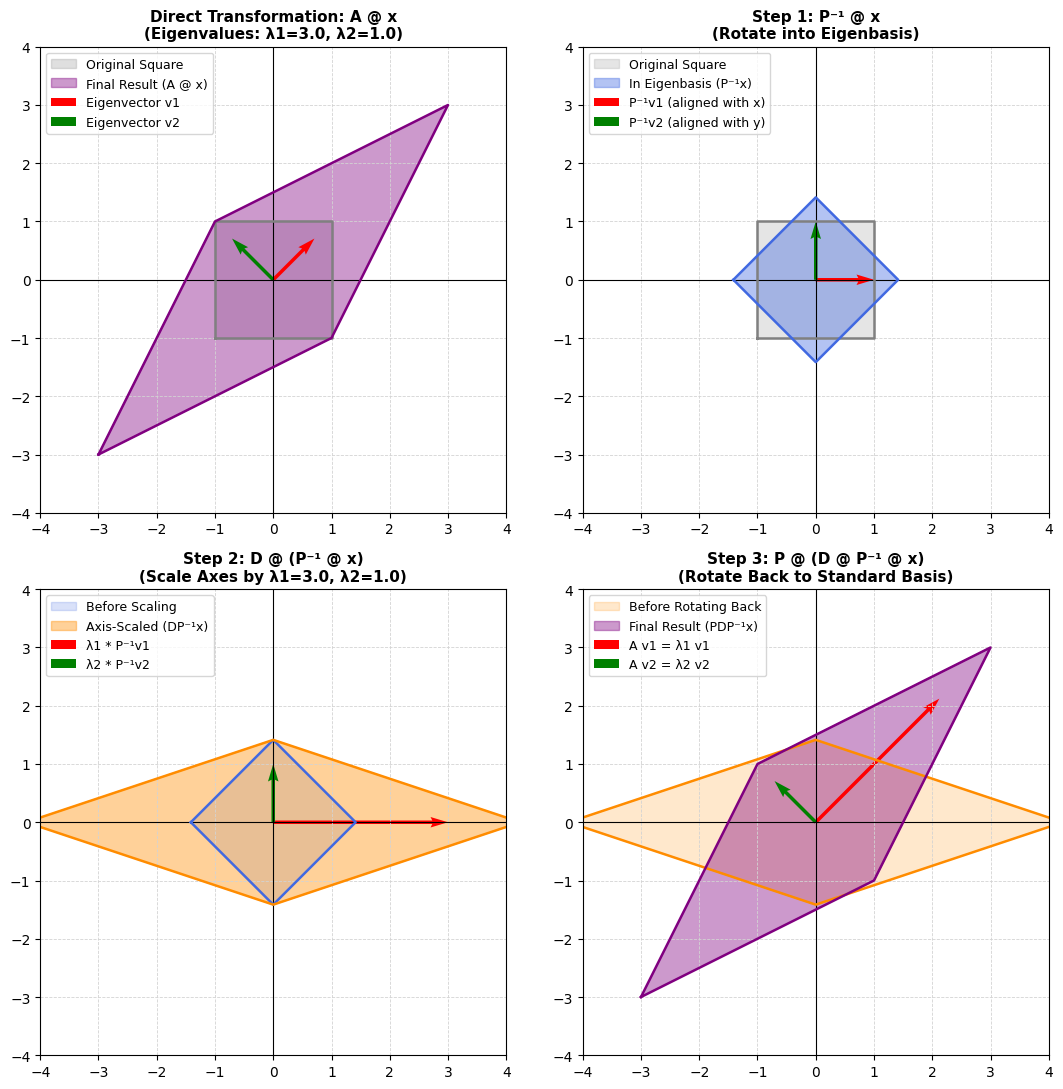

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def setup_ax(ax, title, lim=4):
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.grid(color='lightgray', linestyle='--', linewidth=0.6)
    ax.set_title(title, fontsize=11, fontweight='bold')

def plot_shape(ax, shape, color, label, alpha=0.35):
    ax.plot(shape[0, :], shape[1, :], color=color, linewidth=1.8)
    ax.fill(shape[0, :], shape[1, :], color=color, alpha=alpha, label=label)

# 1. Define a diagonalizable 2x2 matrix (symmetric for clean orthogonal eigenvectors)
A = np.array([
    [2.0, 1.0],
    [1.0, 2.0]
])

# 2. Compute Eigendecomposition: A = P @ D @ P_inv
eigenvalues, P = np.linalg.eig(A)
D = np.diag(eigenvalues)
P_inv = np.linalg.inv(P)

# Verify reconstruction
assert np.allclose(A, P @ D @ P_inv)

# 3. Define Unit Square [-1, 1] x [-1, 1] and basis/eigenvector arrows
square = np.array([
    [-1,  1,  1, -1, -1],
    [-1, -1,  1,  1, -1]
], dtype=float)

# Eigenvector columns of P
v1 = P[:, 0]
v2 = P[:, 1]

# 4. Compute the 3 sequential stages of A = P @ D @ P_inv
step1_shape = P_inv @ square          # Step 1: Change to eigenbasis (P^-1)
step2_shape = D @ step1_shape         # Step 2: Axis-aligned scaling (D)
step3_shape = P @ step2_shape         # Step 3: Change back to standard basis (P)
direct_shape = A @ square             # Direct transformation (A)

# 5. Plot 2x2 Grid
fig, axs = plt.subplots(2, 2, figsize=(11, 11))

# --- Panel 1: Direct Transformation A @ x ---
setup_ax(axs[0, 0], f"Direct Transformation: A @ x\n(Eigenvalues: λ1={eigenvalues[0]:.1f}, λ2={eigenvalues[1]:.1f})")
plot_shape(axs[0, 0], square, 'gray', 'Original Square', alpha=0.25)
plot_shape(axs[0, 0], direct_shape, 'purple', 'Final Result (A @ x)', alpha=0.4)
# Plot eigenvectors on original space
axs[0, 0].quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='red', label='Eigenvector v1')
axs[0, 0].quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='green', label='Eigenvector v2')
axs[0, 0].legend(loc='upper left', fontsize=9)

# --- Panel 2: Step 1 (P^-1 @ x) ---
setup_ax(axs[0, 1], "Step 1: P⁻¹ @ x\n(Rotate into Eigenbasis)")
plot_shape(axs[0, 1], square, 'gray', 'Original Square', alpha=0.2)
plot_shape(axs[0, 1], step1_shape, 'royalblue', 'In Eigenbasis (P⁻¹x)', alpha=0.4)
# In eigenbasis, v1 and v2 align with standard x and y axes!
v1_e = P_inv @ v1
v2_e = P_inv @ v2
axs[0, 1].quiver(0, 0, v1_e[0], v1_e[1], angles='xy', scale_units='xy', scale=1, color='red', label='P⁻¹v1 (aligned with x)')
axs[0, 1].quiver(0, 0, v2_e[0], v2_e[1], angles='xy', scale_units='xy', scale=1, color='green', label='P⁻¹v2 (aligned with y)')
axs[0, 1].legend(loc='upper left', fontsize=9)

# --- Panel 3: Step 2 (D @ P^-1 @ x) ---
setup_ax(axs[1, 0], f"Step 2: D @ (P⁻¹ @ x)\n(Scale Axes by λ1={eigenvalues[0]:.1f}, λ2={eigenvalues[1]:.1f})")
plot_shape(axs[1, 0], step1_shape, 'royalblue', 'Before Scaling', alpha=0.2)
plot_shape(axs[1, 0], step2_shape, 'darkorange', 'Axis-Scaled (DP⁻¹x)', alpha=0.4)
axs[1, 0].quiver(0, 0, eigenvalues[0]*v1_e[0], eigenvalues[0]*v1_e[1], angles='xy', scale_units='xy', scale=1, color='red', label='λ1 * P⁻¹v1')
axs[1, 0].quiver(0, 0, eigenvalues[1]*v2_e[0], eigenvalues[1]*v2_e[1], angles='xy', scale_units='xy', scale=1, color='green', label='λ2 * P⁻¹v2')
axs[1, 0].legend(loc='upper left', fontsize=9)

# --- Panel 4: Step 3 (P @ D @ P^-1 @ x) ---
setup_ax(axs[1, 1], "Step 3: P @ (D @ P⁻¹ @ x)\n(Rotate Back to Standard Basis)")
plot_shape(axs[1, 1], step2_shape, 'darkorange', 'Before Rotating Back', alpha=0.2)
plot_shape(axs[1, 1], step3_shape, 'purple', 'Final Result (PDP⁻¹x)', alpha=0.4)
axs[1, 1].quiver(0, 0, eigenvalues[0]*v1[0], eigenvalues[0]*v1[1], angles='xy', scale_units='xy', scale=1, color='red', label='A v1 = λ1 v1')
axs[1, 1].quiver(0, 0, eigenvalues[1]*v2[0], eigenvalues[1]*v2[1], angles='xy', scale_units='xy', scale=1, color='green', label='A v2 = λ2 v2')
axs[1, 1].legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

## Singular Value Decomposition (SVD)

**Singular Value Decomposition (SVD)** is a matrix factorization method that generalizes the eigendecomposition of a square normal matrix to any $m \times n$ matrix. Given a real matrix $A \in \mathbb{R}^{m \times n}$, its SVD is defined as:

$$A = U \Sigma V^T$$

---

### 1. Anatomy of the Matrices

| Matrix | Dimensions | Type / Property | Mathematical Role |
| :--- | :--- | :--- | :--- |
| **$A$** | $m \times n$ | Any real matrix | The original data or transformation matrix. |
| **$U$** | $m \times m$ | Orthogonal ($U^T U = U U^T = I_m$) | Columns $u_i$ are the **Left Singular Vectors** (orthonormal basis for the output/row space $\mathbb{R}^m$). |
| **$\Sigma$** | $m \times n$ | Diagonal (non-negative entries) | Diagonal entries $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r > 0$ are the **Singular Values** (scaling factors). |
| **$V^T$** | $n \times n$ | Orthogonal ($V^T V = V V^T = I_n$) | Rows of $V^T$ (columns of $V$) are the **Right Singular Vectors** (orthonormal basis for the input/column space $\mathbb{R}^n$). |

---

### 2. Geometric Intuition

Any linear transformation represented by a matrix $A$ can be broken down into three simple geometric operations applied in sequence to a vector $x$ ($Ax = U \Sigma V^T x$):

1. **Rotation / Reflection in Input Space ($V^T x$):** Since $V^T$ is an orthogonal matrix, multiplying $x$ by $V^T$ rotates (or reflects) the vector without changing its length, aligning it with the principal axes (right singular vectors).
2. **Scaling along Coordinate Axes ($\Sigma (V^T x)$):** The diagonal matrix $\Sigma$ stretches or shrinks the rotated vector along the standard coordinate axes by the singular values $\sigma_i$. It may also pad with zeros (if $m > n$) or drop dimensions (if $m < n$).
3. **Rotation / Reflection in Output Space ($U (\Sigma V^T x)$):** Finally, the orthogonal matrix $U$ rotates (or reflects) the scaled vector into its final orientation in the output space $\mathbb{R}^m$.

In short: **SVD transforms a unit sphere in $\mathbb{R}^n$ into a hyper-ellipse in $\mathbb{R}^m$**, where the singular values $\sigma_i$ are the lengths of the semi-axes of the ellipse, and the columns of $U$ point along those axes.

---

### 3. Mathematical Derivation (Connection to Eigenvalues)

How do we actually find $U$, $\Sigma$, and $V$? We connect SVD to the symmetric matrices $A^T A$ and $A A^T$:

#### Finding $V$ and $\Sigma$ via $A^T A$:
$$A^T A = (U \Sigma V^T)^T (U \Sigma V^T) = V \Sigma^T U^T U \Sigma V^T$$
Since $U$ is orthogonal ($U^T U = I$):
$$A^T A = V (\Sigma^T \Sigma) V^T$$
* Notice that $\Sigma^T \Sigma$ is an $n \times n$ diagonal matrix with $\sigma_i^2$ on the diagonal.
* Therefore, the columns of **$V$** are the **eigenvectors of $A^T A$**, and the **singular values $\sigma_i$** are the **square roots of the eigenvalues of $A^T A$** ($\sigma_i = \sqrt{\lambda_i}$).

#### Finding $U$ via $A A^T$:
$$A A^T = (U \Sigma V^T)(U \Sigma V^T)^T = U \Sigma V^T V \Sigma^T U^T = U (\Sigma \Sigma^T) U^T$$
* The columns of **$U$** are the **eigenvectors of $A A^T$**.
* Alternatively, once $V$ and $\sigma_i$ are known, the columns of $U$ can be computed directly via:
$$u_i = \frac{1}{\sigma_i} A v_i \quad \text{for } i = 1, \dots, r$$

---

### 4. Full SVD vs. Reduced (Thin) SVD vs. Truncated SVD

Suppose $A$ is $m \times n$ and has rank $r \le \min(m, n)$:

1. **Full SVD:** $U$ is $m \times m$, $\Sigma$ is $m \times n$, and $V^T$ is $n \times n$.
2. **Reduced (Economy) SVD:** Drops the zero padding in $\Sigma$. If $k = \min(m, n)$, $U$ is $m \times k$, $\Sigma$ is $k \times k$, and $V^T$ is $k \times n$. This is lossless and saves memory.
3. **Truncated SVD (Low-Rank Approximation):** By the **Eckart–Young–Mirsky Theorem**, the best rank-$k$ approximation ($k < r$) of $A$ in terms of Frobenius or spectral norm is obtained by keeping only the top $k$ largest singular values and their corresponding vectors:
$$A_k = \sum_{i=1}^{k} \sigma_i u_i v_i^T = U_k \Sigma_k V_k^T$$

---

### 5. Key Applications
* **Dimensionality Reduction & PCA:** Centering data matrix $X$ and computing its SVD directly yields Principal Component Analysis (PCA). The principal components are $V$, and the projected scores are $U\Sigma$.
* **Data & Image Compression:** Storing only the top $k$ singular values/vectors reduces storage from $m \times n$ numbers to $k(m + n + 1)$ numbers.
* **Noise Reduction:** Small singular values often correspond to random noise; zeroing them out denoises the dataset.
* **Moore–Penrose Pseudoinverse ($A^+$):** Used to solve least-squares linear systems ($Ax \approx b$) when $A$ is not invertible: $A^+ = V \Sigma^+ U^T$, where $\Sigma^+$ reciprocates non-zero singular values ($1/\sigma_i$).
* **Recommender Systems (Collaborative Filtering):** Factorizing sparse user-item rating matrices to predict missing ratings.

1. BASIC SVD & MATRIX RECONSTRUCTION WITH NUMPY
Original Matrix A ((4, 3)):
[[ 3.  2.  2.]
 [ 2.  3. -2.]
 [ 1.  0.  4.]
 [ 0.  1. -1.]]

Left Singular Vectors U ((4, 4)):
[[ 0.7324 -0.2648 -0.4332  0.4537]
 [ 0.1313 -0.8248  0.183  -0.5186]
 [ 0.6638  0.4254  0.5228 -0.3241]
 [-0.0757 -0.2618  0.711   0.6482]]

Singular Values s (1D):
[5.3296 4.9244 0.5878]

Diagonal Matrix Sigma ((4, 3)):
[[5.3296 0.     0.    ]
 [0.     4.9244 0.    ]
 [0.     0.     0.5878]
 [0.     0.     0.    ]]

Right Singular Vectors Vt ((3, 3)):
[[ 0.5861  0.3345  0.738 ]
 [-0.4099 -0.6632  0.6262]
 [-0.6989  0.6695  0.2516]]

Reconstructed Matrix (U @ Sigma @ Vt):
[[ 3.  2.  2.]
 [ 2.  3. -2.]
 [ 1. -0.  4.]
 [-0.  1. -1.]]

Reconstruction matches A? True
U is orthogonal (U.T @ U == I)? True
V is orthogonal (Vt @ Vt.T == I)? True

2. MANUAL SVD FROM SCRATCH (EIGENDECOMPOSITION)
Manual Singular Values: [5.3296 4.9244 0.5878]
NumPy Singular Values:  [5.3296 4.9244 0.5878]
Manual Reconstruction matches A? True


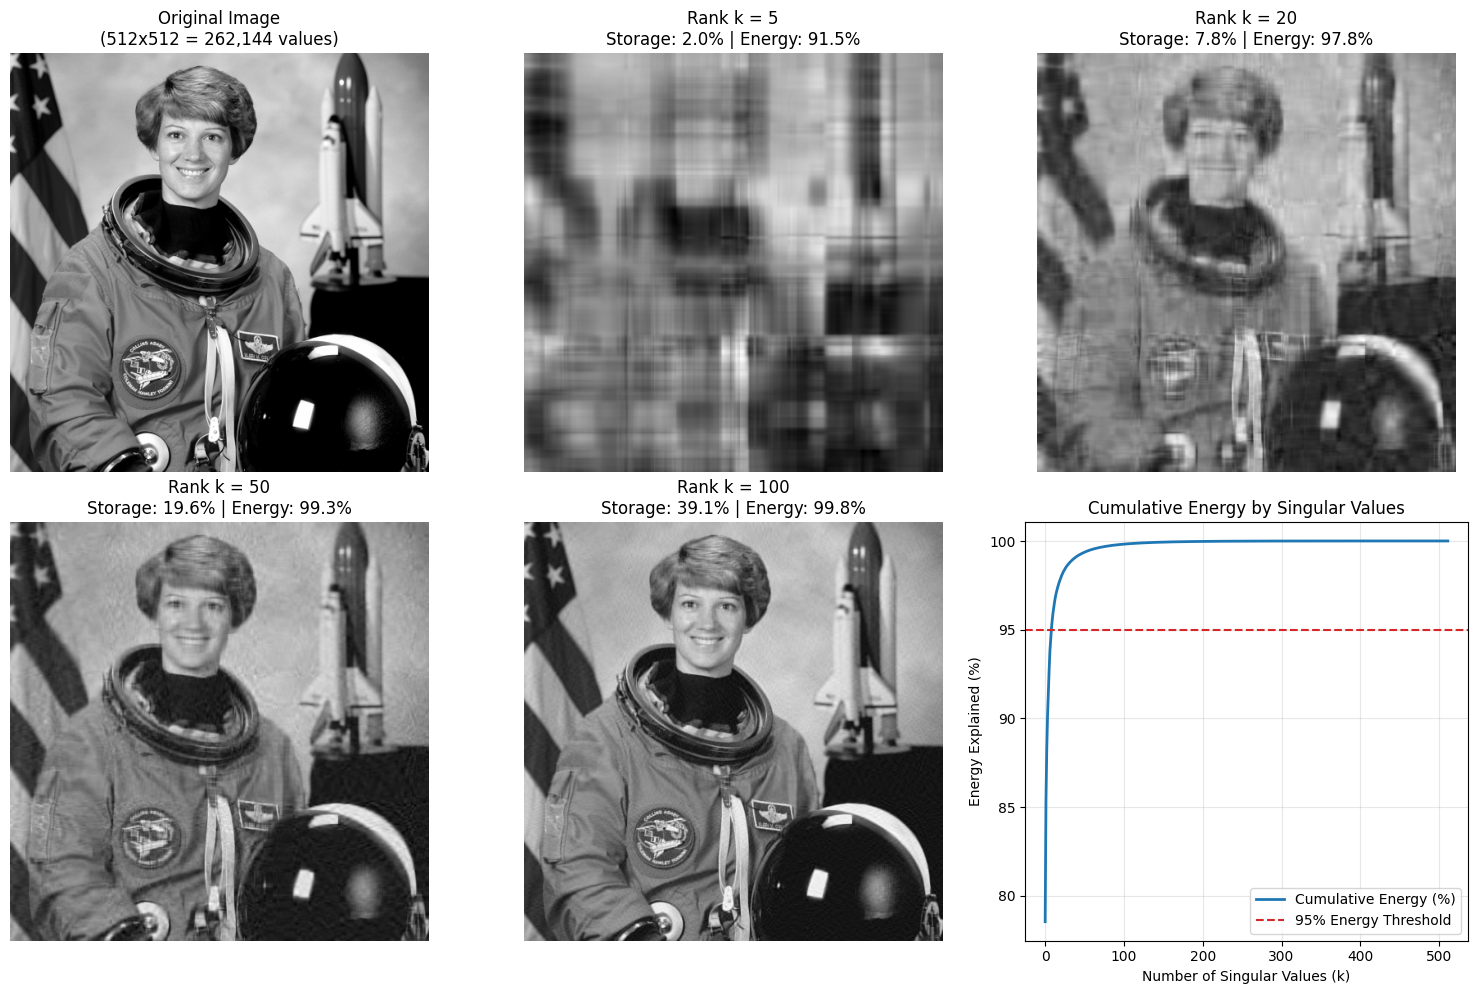

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color

# Set print options for clean matrix output
np.set_printoptions(precision=4, suppress=True)

print("==================================================")
print("1. BASIC SVD & MATRIX RECONSTRUCTION WITH NUMPY")
print("==================================================")

# Create a sample 4x3 matrix A
A = np.array([
    [3, 2,  2],
    [2, 3, -2],
    [1, 0,  4],
    [0, 1, -1]
], dtype=float)

# Compute Full SVD
# Note: np.linalg.svd returns U, s (1D array of singular values), and Vt (V transpose)
U, s, Vt = np.linalg.svd(A, full_matrices=True)

# Construct the full m x n diagonal matrix Sigma from the 1D array s
Sigma = np.zeros(A.shape)
np.fill_diagonal(Sigma, s)

print(f"Original Matrix A ({A.shape}):\n{A}\n")
print(f"Left Singular Vectors U ({U.shape}):\n{U}\n")
print(f"Singular Values s (1D):\n{s}\n")
print(f"Diagonal Matrix Sigma ({Sigma.shape}):\n{Sigma}\n")
print(f"Right Singular Vectors Vt ({Vt.shape}):\n{Vt}\n")

# Reconstruct A and verify
A_reconstructed = U @ Sigma @ Vt
print(f"Reconstructed Matrix (U @ Sigma @ Vt):\n{A_reconstructed}\n")
print(f"Reconstruction matches A? {np.allclose(A, A_reconstructed)}")
print(f"U is orthogonal (U.T @ U == I)? {np.allclose(U.T @ U, np.eye(U.shape[0]))}")
print(f"V is orthogonal (Vt @ Vt.T == I)? {np.allclose(Vt @ Vt.T, np.eye(Vt.shape[0]))}\n")


print("==================================================")
print("2. MANUAL SVD FROM SCRATCH (EIGENDECOMPOSITION)")
print("==================================================")

# Compute A^T * A
AtA = A.T @ A

# Get eigenvalues and eigenvectors of symmetric matrix A^T * A
eigenvalues, V_manual = np.linalg.eigh(AtA)

# Sort eigenvalues and eigenvectors in descending order
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
V_manual = V_manual[:, sort_idx]

# Singular values are square roots of non-negative eigenvalues
s_manual = np.sqrt(np.maximum(eigenvalues, 0))

# Compute U columns using u_i = (A @ v_i) / sigma_i
U_manual_reduced = np.zeros((A.shape[0], len(s_manual)))
for i in range(len(s_manual)):
    if s_manual[i] > 1e-10:
        U_manual_reduced[:, i] = (A @ V_manual[:, i]) / s_manual[i]

# Reconstruct using manual Reduced SVD
A_manual_reconstructed = U_manual_reduced @ np.diag(s_manual) @ V_manual.T
print(f"Manual Singular Values: {s_manual}")
print(f"NumPy Singular Values:  {s}")
print(f"Manual Reconstruction matches A? {np.allclose(A, A_manual_reconstructed)}\n")


print("==================================================")
print("3. LOW-RANK APPROXIMATION & IMAGE COMPRESSION")
print("==================================================")

# Load a sample grayscale image (512 x 512)
img = color.rgb2gray(data.astronaut())
m, n = img.shape

# Perform Economy (Reduced) SVD on the image
U_img, s_img, Vt_img = np.linalg.svd(img, full_matrices=False)

# Ranks k to test for compression
ranks = [5, 20, 50, 100]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Plot Original Image
axes[0].imshow(img, cmap='gray')
axes[0].set_title(f"Original Image\n({m}x{n} = {m*n:,} values)")
axes[0].axis('off')

# Plot Reconstructed Images for each rank k
for idx, k in enumerate(ranks):
    # Truncated SVD: A_k = U[:, :k] @ diag(s[:k]) @ Vt[:k, :]
    img_k = (U_img[:, :k] * s_img[:k]) @ Vt_img[:k, :]

    # Calculate storage ratio: k*(m + n + 1) / (m*n)
    compressed_size = k * (m + n + 1)
    ratio = (compressed_size / (m * n)) * 100

    # Calculate variance (energy) retained
    energy = (np.sum(s_img[:k]**2) / np.sum(s_img**2)) * 100

    axes[idx + 1].imshow(img_k, cmap='gray')
    axes[idx + 1].set_title(
        f"Rank k = {k}\nStorage: {ratio:.1f}% | Energy: {energy:.1f}%"
    )
    axes[idx + 1].axis('off')

# Plot Singular Value Spectrum & Cumulative Energy in the last subplot
cumulative_energy = np.cumsum(s_img**2) / np.sum(s_img**2) * 100
ax_spec = axes[5]
ax_spec.plot(cumulative_energy, color='tab:blue', linewidth=2, label='Cumulative Energy (%)')
ax_spec.axhline(95, color='tab:red', linestyle='--', label='95% Energy Threshold')
ax_spec.set_title("Cumulative Energy by Singular Values")
ax_spec.set_xlabel("Number of Singular Values (k)")
ax_spec.set_ylabel("Energy Explained (%)")
ax_spec.grid(True, alpha=0.3)
ax_spec.legend()

plt.tight_layout()
plt.show()

### linear transformation (and dimensionality reduction)

In [3]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Define the 8 vertices of a unit cube in 3D space
cube = np.array([
    [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],  # Bottom face (v0 - v3)
    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]   # Top face (v4 - v7)
])
vertex_labels = [f"v{i}" for i in range(len(cube))]

# 2. Define the 12 edges
edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),  # Bottom face
    (4, 5), (5, 6), (6, 7), (7, 4),  # Top face
    (0, 4), (1, 5), (2, 6), (3, 7)   # Vertical pillars
]

# 3. Define 2x3 transformation matrix and project onto 2D
A = np.array([[1, 2, 1],
              [2, 1, 0]])

# Clean matrix multiplication: (8x3) @ (3x2) -> (8x2)
transformed_cube = cube @ A.T

# Helper to build single-trace edge coordinates using None separators
def build_edge_coords(vertices, edges, dims=3):
    coords = [[] for _ in range(dims)]
    for i, j in edges:
        for d in range(dims):
            coords[d].extend([vertices[i, d], vertices[j, d], None])
    return coords

x3d, y3d, z3d = build_edge_coords(cube, edges, dims=3)
x2d, y2d = build_edge_coords(transformed_cube, edges, dims=2)

# 4. Create Side-by-Side 3D and 2D Subplots
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scene'}, {'type': 'xy'}]],
    subplot_titles=("Original 3D Unit Cube (R³)", "Projected 2D Cube via Matrix A (R²)")
)

# --- Left Subplot: 3D Cube ---
fig.add_trace(go.Scatter3d(
    x=x3d, y=y3d, z=z3d,
    mode='lines',
    line=dict(color='royalblue', width=4),
    name='3D Edges'
), row=1, col=1)

fig.add_trace(go.Scatter3d(
    x=cube[:, 0], y=cube[:, 1], z=cube[:, 2],
    mode='markers+text',
    text=vertex_labels,
    textposition='top center',
    marker=dict(size=5, color='crimson'),
    name='3D Vertices'
), row=1, col=1)

# --- Right Subplot: 2D Projected Cube ---
fig.add_trace(go.Scatter(
    x=x2d, y=y2d,
    mode='lines',
    line=dict(color='darkorange', width=2.5),
    name='2D Projected Edges'
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=transformed_cube[:, 0], y=transformed_cube[:, 1],
    mode='markers+text',
    text=[f"{lbl} ({x},{y})" for lbl, (x, y) in zip(vertex_labels, transformed_cube)],
    textposition='top center',
    marker=dict(size=8, color='crimson'),
    name='2D Vertices'
), row=1, col=2)

# 5. Lock aspect ratios so geometry isn't visually distorted
fig.update_layout(
    width=1100, height=520,
    scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z', aspectmode='data'),
    xaxis=dict(title='X (Projected)', zeroline=True, gridcolor='lightgray'),
    yaxis=dict(title='Y (Projected)', scaleanchor='x', scaleratio=1, zeroline=True, gridcolor='lightgray'),
    margin=dict(r=20, l=20, b=20, t=50),
    showlegend=True
)

fig.show()